# Setup

In [1]:
#pytorch
%pip install torch torchvision torchaudio

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
#dataset, tokenizer, numerical and plotting libraries
%pip install datasets tokenizers numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
#updating typing_extensions
%pip install --user --upgrade "typing_extensions>=4.10.0"

Note: you may need to restart the kernel to use updated packages.


In [4]:
#importing standard libraries
import gc, hashlib, json, math, random, time
from contextlib import nullcontext
from dataclasses import dataclass, asdict
from pathlib import Path
from importlib.metadata import version

import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

In [5]:
#experiment settings
PROFILE = "full"       
DATA_SOURCE = "tinystories"
RUN_CONTEXT_ABLATION = False
SEED = 2026

#output dir
OUT = Path("tinygpt_runs") / f"{PROFILE}_{DATA_SOURCE}"
OUT.mkdir(parents=True, exist_ok=True)

In [6]:
#GPU or CPU selection
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"

#limiting CPU threads when using CPU
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

#experiment config
if PROFILE == "full":
    assert DATA_SOURCE == "tinystories", "Full training must use real TinyStories."
    assert DEVICE.type == "cuda", "Use smoke mode on CPU; full mode expects a GPU."

assert PROFILE in {"smoke", "full"} and DATA_SOURCE in {"toy", "tinystories"}

In [7]:
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

In [8]:
#enabling FP16 on GPU
def autocast_context():
    return torch.autocast("cuda", dtype=torch.float16) if AMP else nullcontext()

#sync GPU operations
def sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()

In [9]:
#setting seeds and display hardware info
seed_all(SEED)
print("Device:", DEVICE)

if AMP: print(torch.cuda.get_device_name(), "| capability", torch.cuda.get_device_capability())

#lib versions
VERSIONS = {p: version(p) for p in ["torch", "numpy", "tokenizers", "datasets", "matplotlib"]}
print(VERSIONS)

Device: cuda
NVIDIA A100-SXM4-40GB | capability (8, 0)
{'torch': '2.8.0', 'numpy': '2.0.2', 'tokenizers': '0.22.2', 'datasets': '4.5.0', 'matplotlib': '3.9.4'}


# Data Preparation

In [10]:
#training and validation dataset sizes
TRAIN_STORIES = 100_000 if PROFILE == "full" else 128
VAL_STORIES = 2_000 if PROFILE == "full" else 24

In [11]:
#normalizing text and calculating story hashes
def normalized(text): return " ".join(text.split())

def story_hash(text):
    return hashlib.sha256(normalized(text).encode()).hexdigest()

In [12]:
#selecting unique stories and excluding previously seen hashes
def unique_texts(rows, n, excluded=None):
    seen = set() if excluded is None else set(excluded)
    result = []
    for row in rows:
        text = row["text"].strip()
        h = story_hash(text)
        if text and h not in seen:
            result.append(text); seen.add(h)
        if len(result) >= n: break
    assert len(result) == n, "Not enough distinct stories."
    return result

In [13]:
#loading real TinyStories training and validation data
if DATA_SOURCE == "tinystories":
    from datasets import load_dataset
    train_stream = load_dataset("roneneldan/TinyStories", split="train", streaming=True)
    val_stream = load_dataset("roneneldan/TinyStories", split="validation", streaming=True)
    train_texts = unique_texts(train_stream, TRAIN_STORIES)
    val_texts = unique_texts(val_stream, VAL_STORIES, {story_hash(s) for s in train_texts})

#small synthetic dataset for smoke testing
else:
    train_texts = [
        f"Once upon a time, {name} found a {color} {thing}. "
        f"The {thing} was beside a tree. {name} took it home and showed a friend. "
        "They smiled and played together. It was a happy day."
        for name in ["Mia", "Sam", "Lily", "Ben"]
        for color in ["red", "blue", "green", "yellow"]
        for thing in ["ball", "kite", "box", "hat", "toy", "cup", "book", "bell"]
    ]
    val_texts = [
        f"One day, {name} saw a {thing} near the river. "
        f"A friend helped {name} carry it home. They were happy to help each other."
        for name in ["Mia", "Sam", "Lily", "Ben"]
        for thing in ["ball", "kite", "box", "hat", "book", "bell"]
    ]

/home/bap9622/.local/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [14]:
#shuffling training stories and verifying no overlap
random.Random(SEED).shuffle(train_texts)
assert not ({story_hash(t) for t in train_texts} & {story_hash(t) for t in val_texts})

#saving both datasets
for split, texts in [("train", train_texts), ("validation", val_texts)]:
    with (OUT / f"{split}.jsonl").open("w") as f:
        for text in texts: f.write(json.dumps({"text": text}) + "\n")

In [15]:
#dataset info
print("Stories:", len(train_texts), "train;", len(val_texts), "validation")
print(train_texts[0][:500])

Stories: 100000 train; 2000 validation
Once upon a time, there was a nice boy named Tom. Tom liked to play catch with his friends in the park. They would throw a ball and try to catch it, laughing and having fun.

One day, Tom wanted to go on a trip with his family. To go on the trip, Tom needed a passport. His mom said, "Tom, we need to get your passport so we can go on the trip." Tom was very excited.

Tom and his mom went to a big building to get his passport. They waited in a line and then talked to a nice lady. She gave Tom his 


In [16]:
#BPE tokenizer
tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tokenizer.decoder = decoders.ByteLevel()

In [17]:
#configuring vocabulary and special tokens
bpe_trainer = trainers.BpeTrainer(
    vocab_size=8192 if PROFILE == "full" else 512,
    min_frequency=2,
    special_tokens=["<unk>", "<eos>"],
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
    show_progress=False,
)

In [18]:
#training tokenizer using training stories only
tokenizer.train_from_iterator(train_texts, trainer=bpe_trainer)
tokenizer.save(str(OUT / "tokenizer.json"))

In [19]:
#EOS token and vocab size
EOS_ID = tokenizer.token_to_id("<eos>")
VOCAB = tokenizer.get_vocab_size()
assert VOCAB < 65536

In [20]:
#tokenize stories and append EOS after each story
def encode_stream(texts):
    parts = []
    for i in range(0, len(texts), 512):
        for enc in tokenizer.encode_batch(texts[i:i+512]):
            parts.append(np.asarray(enc.ids + [EOS_ID], dtype=np.uint16))
    return np.concatenate(parts)

In [21]:
#encoding training and validation datasets
train_tokens = encode_stream(train_texts)
val_tokens = encode_stream(val_texts)

In [22]:
#token streams
np.save(OUT / "train_tokens.npy", train_tokens)
np.save(OUT / "val_tokens.npy", val_tokens)

In [23]:
#recording hashes
TOKENIZER_HASH = hashlib.sha256((OUT / "tokenizer.json").read_bytes()).hexdigest()

DATA_HASHES = {s: hashlib.sha256((OUT / f"{s}.jsonl").read_bytes()).hexdigest()
               for s in ["train", "validation"]}

In [24]:
#tokenization info
print("Vocabulary:", VOCAB, "| token counts:", len(train_tokens), len(val_tokens))
print("Example pieces:", tokenizer.encode("Once upon a time, a fox found a bell.").tokens)

Vocabulary: 8192 | token counts: 21611495 382835
Example pieces: ['Once', 'Ġupon', 'Ġa', 'Ġtime', ',', 'Ġa', 'Ġfox', 'Ġfound', 'Ġa', 'Ġbell', '.']


In [25]:
#input and next token target sequences
def get_batch(tokens, batch_size, context, rng):
    assert len(tokens) > context
    starts = rng.integers(0, len(tokens) - context, size=batch_size)
    z = np.stack([tokens[s:s+context+1] for s in starts]).astype(np.int64)
    x = torch.from_numpy(z[:, :-1].copy()).to(DEVICE)
    y = torch.from_numpy(z[:, 1:].copy()).to(DEVICE)
    return x, y

# Model

In [26]:
#Transformer architecture parameters
@dataclass
class ModelConfig:
    vocab_size: int
    max_context: int = 256
    n_layer: int = 6
    n_head: int = 6
    d_model: int = 384
    dropout: float = 0.1

In [27]:
#masked multi-head self attention
class CausalAttention(nn.Module):
    def __init__(self, c):
        super().__init__()
        assert c.d_model % c.n_head == 0
        self.heads = c.n_head
        self.head_dim = c.d_model // c.n_head
        self.qkv = nn.Linear(c.d_model, 3*c.d_model)
        self.proj = nn.Linear(c.d_model, c.d_model)
        self.attn_drop = nn.Dropout(c.dropout)
        self.out_drop = nn.Dropout(c.dropout)
        self.register_buffer("allowed", torch.ones(c.max_context, c.max_context,
                                                   dtype=torch.bool).tril(), persistent=False)

    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q, k, v = [t.reshape(B, T, self.heads, self.head_dim).transpose(1, 2)
                   for t in (q, k, v)]
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        scores = scores.masked_fill(~self.allowed[:T, :T], float("-inf"))
        weights = F.softmax(scores.float(), dim=-1).to(v.dtype)
        out = self.attn_drop(weights) @ v
        out = out.transpose(1, 2).contiguous().reshape(B, T, D)
        return self.out_drop(self.proj(out))

In [28]:
#attention and feedforward layers
class Block(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.norm1 = nn.LayerNorm(c.d_model)
        self.attn = CausalAttention(c)
        self.norm2 = nn.LayerNorm(c.d_model)
        self.mlp = nn.Sequential(nn.Linear(c.d_model, 4*c.d_model), nn.GELU(),
                                 nn.Linear(4*c.d_model, c.d_model), nn.Dropout(c.dropout))

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        return x + self.mlp(self.norm2(x))

In [29]:
#decoder only Transformer
class TinyGPT(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.config = c
        self.token = nn.Embedding(c.vocab_size, c.d_model)
        self.position = nn.Embedding(c.max_context, c.d_model)
        self.drop = nn.Dropout(c.dropout)
        self.blocks = nn.ModuleList([Block(c) for _ in range(c.n_layer)])
        self.norm = nn.LayerNorm(c.d_model)
        self.apply(self.initialize)
        for block in self.blocks:
            nn.init.normal_(block.attn.proj.weight, std=0.02/math.sqrt(2*c.n_layer))
            nn.init.normal_(block.mlp[2].weight, std=0.02/math.sqrt(2*c.n_layer))

    @staticmethod
    def initialize(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)

#generating logits and calculating cross entropy loss
    def forward(self, ids, targets=None):
        B, T = ids.shape
        assert 0 < T <= self.config.max_context
        pos = torch.arange(T, device=ids.device)
        h = self.drop(self.token(ids) + self.position(pos)[None, :, :])
        for block in self.blocks: h = block(h)
        h = self.norm(h)
        logits = F.linear(h, self.token.weight)  #weight tying, no second embedding table
        loss = None if targets is None else F.cross_entropy(
            logits.reshape(-1, self.config.vocab_size), targets.reshape(-1))
        return logits, loss

In [30]:
#choosing full or smaller smoke test architecture
model_config = ModelConfig(VOCAB) if PROFILE == "full" else ModelConfig(
    VOCAB, max_context=32, n_layer=2, n_head=2, d_model=64, dropout=0.0)

print(model_config)

ModelConfig(vocab_size=8192, max_context=256, n_layer=6, n_head=6, d_model=384, dropout=0.1)


# Sanity Checks

In [31]:
#checking that targets are shifted by exactly one token
x_example, y_example = get_batch(train_tokens, 2, 16, np.random.default_rng(SEED))
assert torch.equal(x_example[:, 1:], y_example[:, :-1])

In [32]:
#example batch
print("x:", tokenizer.decode(x_example[0].tolist()))
print("y:", tokenizer.decode(y_example[0].tolist()))

x:  a cartoon on his laptop, but unfortunately, he couldn't find it
y:  cartoon on his laptop, but unfortunately, he couldn't find it.


In [33]:
#verifying causal masking and cross entropy calculations
seed_all(SEED)
check_config = ModelConfig(VOCAB, max_context=16, n_layer=1, n_head=2, d_model=32, dropout=0.0)
check = TinyGPT(check_config).to(DEVICE).eval()
x, y = get_batch(train_tokens, 2, 16, np.random.default_rng(42))
changed = x.clone()
changed[:, 8:] = (changed[:, 8:] + 7) % VOCAB

with torch.no_grad():
    first, loss = check(x, y)
    altered, _ = check(changed)
    assert torch.allclose(first[:, :8], altered[:, :8], atol=1e-6, rtol=1e-5)
    manual_loss = -first.log_softmax(-1).gather(-1, y[..., None]).mean()
    assert torch.allclose(loss, manual_loss, atol=1e-6)

In [34]:
#gradients, learning check
optimizer_check = torch.optim.AdamW(check.parameters(), lr=0.01, weight_decay=0.0)
initial_loss = loss.item()
check.train()

for _ in range(120):
    optimizer_check.zero_grad(set_to_none=True)
    _, loss = check(x, y)
    loss.backward()
    assert all(p.grad is None or torch.isfinite(p.grad).all() for p in check.parameters())
    optimizer_check.step()

with torch.no_grad(): final_loss = check(x, y)[1].item()

assert final_loss < 0.5 * initial_loss, (initial_loss, final_loss)
print(f"PASS: causality, cross-entropy, gradients; fixed-batch loss {initial_loss:.3f} -> {final_loss:.3f}")

del check, optimizer_check, first, altered, loss, manual_loss
if AMP: torch.cuda.empty_cache()

PASS: causality, cross-entropy, gradients; fixed-batch loss 8.999 -> 0.004


In [35]:
#overfitting diagnostic
seed_all(SEED + 1)
from dataclasses import replace

fit_config = replace(model_config, dropout=0.0)
fit_model = TinyGPT(fit_config).to(DEVICE)
fit_context = min(64, fit_config.max_context)
fit_x, fit_y = get_batch(train_tokens, 2, fit_context, np.random.default_rng(SEED + 1))
fit_optimizer = torch.optim.AdamW(fit_model.parameters(), lr=1e-3, weight_decay=0.0)
fit_trace = []
fit_model.train()

TinyGPT(
  (token): Embedding(8192, 384)
  (position): Embedding(256, 384)
  (drop): Dropout(p=0.0, inplace=False)
  (blocks): ModuleList(
    (0-5): 6 x Block(
      (norm1): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
      (attn): CausalAttention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (out_drop): Dropout(p=0.0, inplace=False)
      )
      (norm2): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
      (mlp): Sequential(
        (0): Linear(in_features=384, out_features=1536, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=1536, out_features=384, bias=True)
        (3): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
)

In [36]:
#test overfitting
for iteration in range(1501):
    fit_optimizer.zero_grad(set_to_none=True)
    _, fit_loss = fit_model(fit_x, fit_y)
    fit_value = fit_loss.item()

    if not math.isfinite(fit_value):
        raise RuntimeError("Non-finite fixed batch diagnostic loss")

    if iteration % 10 == 0 or fit_value < 0.02:
        fit_trace.append({"iteration": iteration, "loss": fit_value})

    if fit_value < 0.02:
        break
    if iteration == 1500:
        break

    fit_loss.backward()
    nn.utils.clip_grad_norm_(fit_model.parameters(), 1.0, error_if_nonfinite=True)
    fit_optimizer.step()

assert fit_value < 0.02, "Near zero overfit check failed. Debug before main training."

Production architecture fixed batch loss: 9.000768661499023 -> 0.017074786126613617


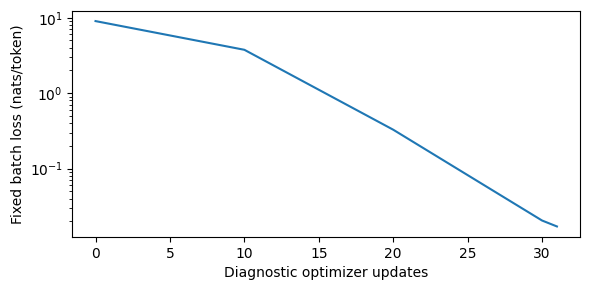

In [37]:
#loss history and diagnostic plot
(OUT / "fixed_batch_overfit.json").write_text(json.dumps(fit_trace, indent=2))
print("Production architecture fixed batch loss:", fit_trace[0]["loss"], "->", fit_value)

fig, ax = plt.subplots(figsize=(6, 3))
ax.semilogy([r["iteration"] for r in fit_trace], [r["loss"] for r in fit_trace])
ax.set(xlabel="Diagnostic optimizer updates", ylabel="Fixed batch loss (nats/token)")
fig.tight_layout(); fig.savefig(OUT / "fixed_batch_overfit.png", dpi=160); plt.show()

#releasing diagnostic resources
del fit_model, fit_optimizer, fit_x, fit_y, fit_loss
for key in ["x", "y", "changed", "x_example", "y_example"]:
    globals().pop(key, None)
gc.collect()
if AMP: torch.cuda.empty_cache()

# Training

In [38]:
#context and val budget
BASE_CONTEXT = 256 if PROFILE == "full" else 32
SHORT_CONTEXT = 64 if PROFILE == "full" else 8
VAL_TARGETS = min(32768 if PROFILE == "full" else 256,
                  ((len(val_tokens)-1)//BASE_CONTEXT)*BASE_CONTEXT)
assert VAL_TARGETS > 0

In [39]:
#validation cross entropy
@torch.no_grad()
def evaluate(model, context, batch_size=8):
    previous_mode = model.training
    model.eval()
    total_nll = 0.0
    count = 0
    for start in range(0, VAL_TARGETS, batch_size*context):
        stops = range(start, min(start+batch_size*context, VAL_TARGETS), context)
        z = np.stack([val_tokens[s:s+context+1] for s in stops]).astype(np.int64)
        x = torch.from_numpy(z[:, :-1].copy()).to(DEVICE)
        y = torch.from_numpy(z[:, 1:].copy()).to(DEVICE)
        with autocast_context(): _, loss = model(x, y)
        total_nll += loss.item()*y.numel(); count += y.numel()
    model.train(previous_mode)
    assert count == VAL_TARGETS
    return total_nll/count

In [40]:
#generate text one token at a time
@torch.no_grad()
def generate(model, prompt, context, max_new_tokens=80, temperature=1.0, top_k=None,
             greedy=False, seed=7):
    assert temperature > 0
    previous_mode = model.training
    model.eval()
    prefix = tokenizer.encode(prompt).ids or [EOS_ID]
    ids = torch.tensor([prefix], dtype=torch.long, device=DEVICE)
    rng = torch.Generator(device=DEVICE).manual_seed(seed)

    for _ in range(max_new_tokens):
        with autocast_context(): logits, _ = model(ids[:, -context:])
        last = logits[:, -1, :].float()

        if greedy:
            next_id = last.argmax(dim=-1, keepdim=True)
        else:
            last = last/temperature
            if top_k is not None:
                assert 1 <= top_k <= VOCAB
                threshold = torch.topk(last, top_k).values[:, -1:]
                last = last.masked_fill(last < threshold, float("-inf"))
            next_id = torch.multinomial(last.softmax(-1), 1, generator=rng)

        ids = torch.cat([ids, next_id], dim=1)
        if next_id.item() == EOS_ID: break

    model.train(previous_mode)
    return tokenizer.decode(ids[0].tolist(), skip_special_tokens=True)

In [41]:
#defining fixed story prompts
PROMPTS = ["Once upon a time, a little fox", "Mia found a strange box in the garden.",
           "Ben wanted to help his friend, but"]

#generating samples with fixed settings
def sample_set(model, context):
    return [generate(model, p, context, max_new_tokens=80 if PROFILE == "full" else 20,
                     temperature=0.8, top_k=min(50, VOCAB), seed=100+i)
            for i, p in enumerate(PROMPTS)]

#settings
SAMPLING = {"max_new_tokens": 80 if PROFILE == "full" else 20,
            "temperature": 0.8, "top_k": min(50, VOCAB),
            "seeds": [100, 101, 102], "stop_on_eos": True}

(OUT / "prompts_and_sampling.json").write_text(
    json.dumps({"prompts": PROMPTS, "sampling": SAMPLING}, indent=2))
print("Fixed validation target tokens:", VAL_TARGETS)

Fixed validation target tokens: 32768


In [42]:
#training hyperparameters
@dataclass
class TrainConfig:
    context: int
    microbatch: int = 8
    tokens_per_update: int = 16384
    token_budget: int = 25_000_000
    lr: float = 3e-4
    weight_decay: float = 0.1
    eval_every: int = 100
    seed: int = SEED

In [43]:
#choosing full or smoke test training settings
def make_training_config(context):
    if PROFILE == "full": return TrainConfig(context=context)
    return TrainConfig(context=context, microbatch=4, tokens_per_update=256,
                       token_budget=5120, lr=1e-3, eval_every=10)

In [44]:
#apply weight decay to matrix parameters only
def build_optimizer(model, c):
    params = list(model.parameters())  #tied embeddings occur only once
    return torch.optim.AdamW([
        {"params": [p for p in params if p.ndim >= 2], "weight_decay": c.weight_decay},
        {"params": [p for p in params if p.ndim < 2], "weight_decay": 0.0}],
        lr=c.lr, betas=(0.9, 0.95))

In [45]:
#training the model and evaluation
def train_run(c, name):
    assert c.tokens_per_update % (c.microbatch * c.context) == 0

    accumulation = c.tokens_per_update // (c.microbatch * c.context)
    updates = math.ceil(c.token_budget / c.tokens_per_update)
    warmup = max(1, min(100, updates // 10))

    #directory settings
    run_dir = OUT / name
    if (run_dir / "manifest.json").exists():
        suffix = 2
        while (OUT / f"{name}_run{suffix}" / "manifest.json").exists():
            suffix += 1
        run_dir = OUT / f"{name}_run{suffix}"

    run_dir.mkdir(parents=True, exist_ok=True)

    seed_all(c.seed)
    model = TinyGPT(model_config).to(DEVICE)
    optimizer = build_optimizer(model, c)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    rng = np.random.default_rng(c.seed)

    manifest = {
        "model": asdict(model_config),
        "training": asdict(c),
        "versions": VERSIONS,
        "tokenizer_sha256": TOKENIZER_HASH,
        "data_sha256": DATA_HASHES,
        "profile": PROFILE,
        "data_source": DATA_SOURCE,
        "validation_target_tokens": VAL_TARGETS,
        "prompts": PROMPTS,
        "sampling": SAMPLING
    }
    (run_dir / "manifest.json").write_text(json.dumps(manifest, indent=2))

    best = float("inf")
    best_step = 0
    history = []
    sample_history = {"initial": sample_set(model, c.context)}

    initial_val = evaluate(model, c.context)
    history.append({
        "step": 0,
        "tokens": 0,
        "train_loss": None,
        "val_loss": initial_val
    })
    best = initial_val

    #checkpoint stages
    def save_stage(stage, step):
        torch.save({
            "model": model.state_dict(),
            "model_config": asdict(model_config),
            "context": c.context,
            "step": step,
            "tokens": step * c.tokens_per_update,
            "tokenizer_sha256": TOKENIZER_HASH
        }, run_dir / f"{stage}.pt")

    save_stage("initial", 0)

    torch.save({
        "model": model.state_dict(),
        "model_config": asdict(model_config),
        "context": c.context,
        "step": 0,
        "val_loss": initial_val,
        "tokenizer_sha256": TOKENIZER_HASH
    }, run_dir / "best.pt")

    stage_tokens = {"initial": 0}
    training_seconds = 0.0
    skipped = 0

    if AMP:
        torch.cuda.reset_peak_memory_stats()

    sync()
    wall_start = time.perf_counter()
    rolling_nll = 0.0
    rolling_steps = 0

    #training updates
    for step in range(1, updates + 1):
        model.train()

        if step <= warmup:
            lr = c.lr * step / warmup
        else:
            progress = (step - warmup) / max(1, updates - warmup)
            lr = c.lr * (
                0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * progress))
            )

        for group in optimizer.param_groups:
            group["lr"] = lr

        sync()
        tick = time.perf_counter()
        optimizer.zero_grad(set_to_none=True)
        step_loss = 0.0

        #gradients
        for _ in range(accumulation):
            x, y = get_batch(
                train_tokens, c.microbatch, c.context, rng
            )

            with autocast_context():
                _, loss = model(x, y)

            if not torch.isfinite(loss):
                raise RuntimeError(
                    "Non-finite loss: inspect LR/precision."
                )

            step_loss += loss.detach().float().item() / accumulation
            scaler.scale(loss / accumulation).backward()

        #clipping gradients and updating weights
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        old_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        skipped += int(scaler.get_scale() < old_scale)

        sync()
        training_seconds += time.perf_counter() - tick
        rolling_nll += step_loss
        rolling_steps += 1

        #halfway samples
        if step == max(1, updates // 2):
            sample_history["halfway"] = sample_set(model, c.context)
            stage_tokens["halfway"] = step * c.tokens_per_update
            save_stage("halfway", step)

        #best checkpoint eval
        if step % c.eval_every == 0 or step == updates:
            val_loss = evaluate(model, c.context)

            record = {
                "step": step,
                "tokens": step * c.tokens_per_update,
                "train_loss": rolling_nll / rolling_steps,
                "val_loss": val_loss,
                "lr": lr,
                "training_seconds": training_seconds
            }
            history.append(record)
            rolling_nll = 0.0
            rolling_steps = 0

            if val_loss < best:
                best = val_loss
                best_step = step

                torch.save({
                    "model": model.state_dict(),
                    "model_config": asdict(model_config),
                    "context": c.context,
                    "step": step,
                    "val_loss": val_loss,
                    "tokenizer_sha256": TOKENIZER_HASH
                }, run_dir / "best.pt")

            (run_dir / "history.json").write_text(
                json.dumps(history, indent=2)
            )

            print(
                f"{name}: step {step}/{updates}, "
                f"tokens {record['tokens']:,}, "
                f"train {record['train_loss']:.3f}, "
                f"validation {val_loss:.3f}"
            )

    #final samples and checkpoints
    sample_history["final"] = sample_set(model, c.context)
    stage_tokens["final"] = updates * c.tokens_per_update
    save_stage("final", updates)

    (run_dir / "stage_tokens.json").write_text(
        json.dumps(stage_tokens, indent=2)
    )
    (run_dir / "samples.json").write_text(
        json.dumps(sample_history, indent=2)
    )

    torch.save({
        "model": model.state_dict(),
        "model_config": asdict(model_config),
        "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict(),
        "step": updates,
        "tokenizer_sha256": TOKENIZER_HASH
    }, run_dir / "last.pt")

    #training metrics
    sync()

    summary = {
        "run_directory": str(run_dir),
        "parameters": sum(p.numel() for p in model.parameters()),
        "processed_tokens": updates * c.tokens_per_update,
        "best_val_loss": best,
        "best_val_perplexity": math.exp(best),
        "best_step": best_step,
        "best_tokens": best_step * c.tokens_per_update,
        "microbatch": c.microbatch,
        "accumulation_steps": accumulation,
        "effective_batch_sequences": c.tokens_per_update // c.context,
        "warmup_updates": warmup,
        "validation_target_tokens": VAL_TARGETS,
        "gpu_name": torch.cuda.get_device_name() if AMP else None,
        "training_seconds": training_seconds,
        "wall_seconds_excluding_initial_evaluation":
            time.perf_counter() - wall_start,
        "training_tokens_per_second":
            updates * c.tokens_per_update / training_seconds
            if training_seconds > 0 else None,
        "peak_allocated_GiB":
            torch.cuda.max_memory_allocated() / 2**30 if AMP else None,
        "peak_reserved_GiB":
            torch.cuda.max_memory_reserved() / 2**30 if AMP else None,
        "amp_skipped_updates": skipped
    }

    (run_dir / "summary.json").write_text(
        json.dumps(summary, indent=2)
    )
    print(json.dumps(summary, indent=2))

    #release resources
    del model, optimizer, scaler
    gc.collect()

    if AMP:
        torch.cuda.empty_cache()

    return run_dir

# Experiments

In [ ]:
#experiment
main_training = make_training_config(BASE_CONTEXT)
main_dir = train_run(main_training, f"context_{BASE_CONTEXT}")
print("Results saved to:", main_dir)

context_256: step 100/1526, tokens 1,638,400, train 6.433, validation 4.257
context_256: step 200/1526, tokens 3,276,800, train 4.130, validation 3.563
context_256: step 300/1526, tokens 4,915,200, train 3.670, validation 3.204
context_256: step 400/1526, tokens 6,553,600, train 3.397, validation 2.938
context_256: step 500/1526, tokens 8,192,000, train 3.200, validation 2.763
context_256: step 600/1526, tokens 9,830,400, train 3.061, validation 2.648
context_256: step 700/1526, tokens 11,468,800, train 2.955, validation 2.547
context_256: step 800/1526, tokens 13,107,200, train 2.870, validation 2.461
context_256: step 900/1526, tokens 14,745,600, train 2.810, validation 2.400
context_256: step 1000/1526, tokens 16,384,000, train 2.754, validation 2.348
context_256: step 1100/1526, tokens 18,022,400, train 2.703, validation 2.305


# Evaluation

In [ ]:
#owest validation loss checkpoint
checkpoint = torch.load(main_dir/"best.pt", map_location=DEVICE, weights_only=True)
assert checkpoint["tokenizer_sha256"] == TOKENIZER_HASH

best_model = TinyGPT(ModelConfig(**checkpoint["model_config"])).to(DEVICE)
best_model.load_state_dict(checkpoint["model"])
best_model.eval()

In [ ]:
#verifying reloaded logits
with torch.no_grad():
    xx, _ = get_batch(train_tokens, 1, min(16, BASE_CONTEXT), np.random.default_rng(1))
    expected = best_model(xx)[0].clone()
    restored = TinyGPT(ModelConfig(**checkpoint["model_config"])).to(DEVICE).eval()
    restored.load_state_dict(checkpoint["model"])
    assert torch.allclose(expected, restored(xx)[0], atol=1e-6, rtol=1e-5)

del restored
print("PASS: checkpoint round-trip")

In [ ]:
#training history and loss curves
history = json.loads((main_dir/"history.json").read_text())
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot([h["tokens"] for h in history], [h["val_loss"] for h in history], "o-", label="validation")
trained = [h for h in history if h["train_loss"] is not None]
ax.plot([h["tokens"] for h in trained], [h["train_loss"] for h in trained], "o-", label="training")

ax.set(xlabel="Processed target tokens", ylabel="Cross-entropy (nats/token)",
       title=f"{PROFILE} / {DATA_SOURCE} (training dropout on, validation dropout off)")
ax.legend(); fig.tight_layout()
fig.savefig(main_dir/"loss_curves.png", dpi=140)
plt.show()

In [ ]:
#comparing samples from initial, halfway and final training stages
print("Samples across training:")
for stage, samples in json.loads((main_dir/"samples.json").read_text()).items():
    print("\n", stage.upper())
    for sample in samples: print(sample, "\n")

In [ ]:
#comparing decoding strategies
decoding_samples = {}

for label, options in [
    ("greedy", {"greedy": True}),
    ("temperature_0.7", {"temperature": 0.7}),
    ("top50_temperature_1", {"temperature": 1.0, "top_k": min(50, VOCAB)})
]:
    decoding_samples[label] = [generate(best_model, p, BASE_CONTEXT,
        max_new_tokens=80 if PROFILE == "full" else 20, seed=100+i, **options)
        for i, p in enumerate(PROMPTS)]
    print("\n", label)
    for s in decoding_samples[label]: print(s, "\n")

# Save decoding comparisons
(main_dir/"decoding_samples.json").write_text(json.dumps(decoding_samples, indent=2))

In [ ]:
#loss history
import csv

history = json.loads((main_dir / "history.json").read_text())
fields = sorted(set().union(*(row.keys() for row in history)))

with (main_dir / "loss_history.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader(); writer.writerows(history)

# Results

In [ ]:
#summary metrics
summary = json.loads((main_dir / "summary.json").read_text())

with (main_dir / "summary.csv").open("w", newline="") as f:
    writer = csv.writer(f); writer.writerow(["metric", "value"])
    writer.writerows(summary.items())

In [ ]:
#load samples
samples = json.loads((main_dir / "samples.json").read_text())
stage_tokens = json.loads((main_dir / "stage_tokens.json").read_text())

#comparison
lines = ["# Three fixed prompts across training", "",
         "Settings: temperature 0.8; top-k 50 (or vocabulary size if smaller); "
         "maximum 80 new tokens in full mode; stop on EOS. Text includes prompt.", ""]

for i, prompt in enumerate(PROMPTS):
    lines += [f"## Prompt {i+1}: {prompt}", ""]
    for stage in ["initial", "halfway", "final"]:
        lines += [f"### {stage}: {stage_tokens[stage]:,} processed target tokens", "",
                  samples[stage][i], ""]

(main_dir / "generation_comparison.md").write_text("\n".join(lines))

In [ ]:
#final results and AMP updates
print("Main metrics:")
for key, value in summary.items(): print(f"{key}: {value}")

if summary["amp_skipped_updates"]:
    print("Report AMP skipped updates; inspect their frequency before interpreting training.")

print("Required samples, CSV metrics, checkpoints and figures saved under", main_dir)